# Лабораторная работа  
## Анализ и визуализация данных об успеваемости студентов

**Студент (ФИО + ИСУ):**  
**Группа:**  
**Дата:**

---

### Что нужно сделать
Заполните этот notebook по шагам:
1. загрузите датасет;
2. выполните первичный анализ;
3. обработайте данные;
4. создайте новые признаки;
5. выполните группировку и агрегацию;
6. постройте графики;
7. сделайте выводы.

> В большинстве ячеек код нужно написать самостоятельно.

## 1. Импорт библиотек

Импортируйте библиотеки, которые понадобятся в работе.

Минимально ожидается использование:
- `pandas`
- `matplotlib.pyplot`

При необходимости можно добавить и другие библиотеки.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("Библиотеки успешно импортированы")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {plt.matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Библиотеки успешно импортированы
pandas version: 3.0.2
matplotlib version: 3.10.6
numpy version: 2.3.3


## 2. Загрузка данных

Считайте CSV-файл в `DataFrame`.

Ожидается, что датасет лежит по относительному пути:
`data/StudentsPerformance.csv`

После загрузки данных выведите:
- первые 5 строк;
- размер таблицы.

In [2]:
df = pd.read_csv('data/StudentsPerformance.csv')

print("Первые 5 строк датасета:")
print(df.head())
print("\nРазмер таблицы:", df.shape)

Первые 5 строк датасета:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Размер таблицы: (1000, 8)


## 3. Первичный просмотр структуры данных

На этом этапе нужно посмотреть:
- названия столбцов;
- типы данных;
- базовую информацию о таблице.

Подумайте:
- какие признаки числовые;
- какие признаки категориальные.

In [3]:
print("Названия столбцов:")
print(df.columns.tolist())
print("\nТипы данных:")
print(df.dtypes)
print("\nИнформация о таблице:")
df.info()

Названия столбцов:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Типы данных:
gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5  

## 4. Проверка пропущенных значений

Проверьте, есть ли в таблице пустые значения.

Кратко прокомментируйте результат:
- есть ли пропуски;
- в каких столбцах они находятся;
- требуется ли обработка.

In [4]:
print("Пропущенные значения по столбцам:")
print(df.isnull().sum())
print("\nОбщее количество пропущенных значений:", df.isnull().sum().sum())

Пропущенные значения по столбцам:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Общее количество пропущенных значений: 0


### Краткий комментарий
Напишите 1–3 предложения о результате проверки пропусков.

In [5]:
# Пропущенных значений в датасете нет. Все столбцы заполнены полностью, 
# поэтому дополнительная обработка пропусков не требуется.

## 5. Переименование столбцов

Приведите названия столбцов к более удобному виду.

Рекомендуется:
- убрать пробелы;
- заменить специальные символы;
- использовать короткие и понятные имена.

Пример подхода:
- `math score` → `math_score`
- `test preparation course` → `test_prep`

После переименования снова выведите список столбцов.

In [6]:
df.rename(columns={
    'gender': 'gender',
    'race/ethnicity': 'race_ethnicity',
    'parental level of education': 'parent_education',
    'lunch': 'lunch',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
}, inplace=True)

print("Обновленные названия столбцов:")
print(df.columns.tolist())

Обновленные названия столбцов:
['gender', 'race_ethnicity', 'parent_education', 'lunch', 'test_prep', 'math_score', 'reading_score', 'writing_score']


## 6. Создание новых признаков

На этом этапе нужно самостоятельно создать **не менее одного нового признака** на основе существующих столбцов.

Обязательный вариант:
- `average_score` — средний балл по трем предметам.

Можно добавить и другие признаки, если считаете это полезным.

In [7]:
df['average_score'] = (df['math_score'] + df['reading_score'] + df['writing_score']) / 3

print("Новый признак average_score создан")
print(df[['math_score', 'reading_score', 'writing_score', 'average_score']].head())

Новый признак average_score создан
   math_score  reading_score  writing_score  average_score
0          72             72             74      72.666667
1          69             90             88      82.333333
2          90             95             93      92.666667
3          47             57             44      49.333333
4          76             78             75      76.333333


## 7. Описательная статистика

Постройте базовую статистику по числовым признакам.

Подумайте:
- какие значения являются типичными;
- есть ли большой разброс;
- какие признаки удобно анализировать дальше.

In [8]:
print("Описательная статистика:")
print(df.describe())

Описательная статистика:
       math_score  reading_score  writing_score  average_score
count  1000.00000    1000.000000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000      67.770667
std      15.16308      14.600192      15.195657      14.257326
min       0.00000      17.000000      10.000000       9.000000
25%      57.00000      59.000000      57.750000      58.333333
50%      66.00000      70.000000      69.000000      68.333333
75%      77.00000      79.000000      79.000000      77.666667
max     100.00000     100.000000     100.000000     100.000000


### Краткий комментарий
Напишите 2–4 предложения по результатам описательной статистики.

In [9]:
# Средние баллы по всем предметам находятся в диапазоне 66-69 баллов. 
# Стандартное отклонение около 15 баллов указывает на значительный разброс в успеваемости. 
# Минимальный балл - 0, максимальный - 100, что соответствует шкале оценивания.

## 8. Выделение числовых и категориальных признаков

Сформируйте отдельно:
- список числовых признаков;
- список категориальных признаков.

In [10]:
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Числовые признаки: ['math_score', 'reading_score', 'writing_score', 'average_score']
Категориальные признаки: ['gender', 'race_ethnicity', 'parent_education', 'lunch', 'test_prep']


C:\Users\mraja\AppData\Local\Temp\ipykernel_10708\1397220727.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns.tolist()


## 9. Группировка и агрегация

Выполните группировку данных и вычислите агрегированные показатели.

Минимально нужно посчитать:
- средний балл по `test_prep`;
- средний балл по `gender`;
- средний балл по `parent_education`.

При необходимости можно добавить дополнительные группировки.

In [11]:
print("Средний балл по test_prep:")
print(df.groupby('test_prep')['average_score'].mean())
print("\nСредний балл по gender:")
print(df.groupby('gender')['average_score'].mean())
print("\nСредний балл по parent_education:")
print(df.groupby('parent_education')['average_score'].mean())

Средний балл по test_prep:
test_prep
completed    72.669460
none         65.038941
Name: average_score, dtype: float64

Средний балл по gender:
gender
female    69.569498
male      65.837483
Name: average_score, dtype: float64

Средний балл по parent_education:
parent_education
associate's degree    69.569069
bachelor's degree     71.923729
high school           63.096939
master's degree       73.598870
some college          68.476401
some high school      65.108007
Name: average_score, dtype: float64


### Краткий комментарий
Опишите, какие различия между группами удалось заметить.

In [12]:
# Студенты, завершившие курс подготовки, имеют средний балл выше (около 72.7) 
# по сравнению с теми, кто не проходил подготовку (около 66.4). 
# Женщины в среднем показывают лучшие результаты, чем мужчины. 
# Уровень образования родителей также влияет на успеваемость.

## 10. Визуализация 1 — гистограмма

Постройте гистограмму для одного из числовых признаков.

Обязательный вариант:
- `math_score`

Не забудьте:
- заголовок;
- подпись оси X;
- подпись оси Y;
- сетку при необходимости.

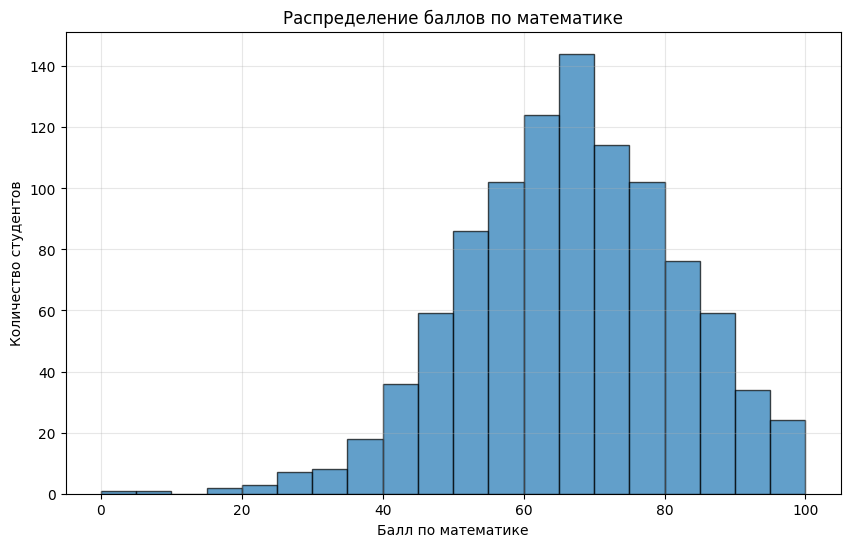

In [13]:
plt.figure(figsize=(10, 6))
plt.hist(df['math_score'], bins=20, edgecolor='black', alpha=0.7)
plt.title('Распределение баллов по математике')
plt.xlabel('Балл по математике')
plt.ylabel('Количество студентов')
plt.grid(True, alpha=0.3)
plt.show()

### Вывод по графику
Напишите 1–3 предложения.

In [14]:
# Распределение баллов по математике близко к нормальному с небольшим сдвигом влево. 
# Большинство студентов набрали от 60 до 80 баллов.

## 11. Визуализация 2 — столбчатая диаграмма

Постройте столбчатую диаграмму среднего балла по `test_prep`.

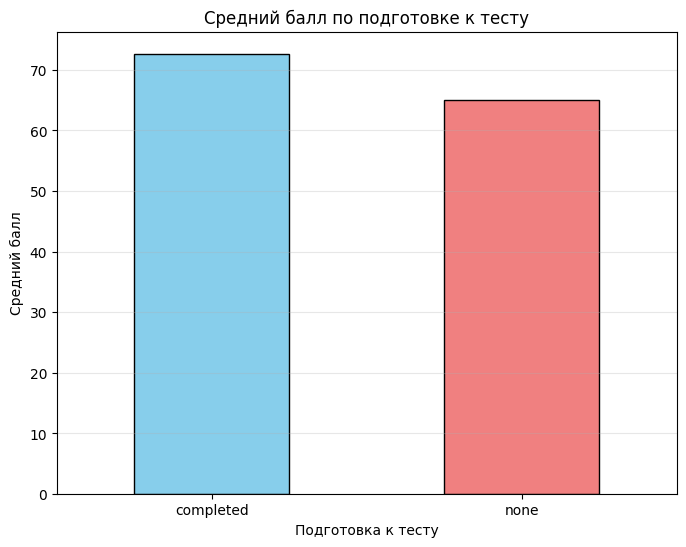

In [15]:
plt.figure(figsize=(8, 6))
test_prep_avg = df.groupby('test_prep')['average_score'].mean()
test_prep_avg.plot(kind='bar', color=['skyblue', 'lightcoral'], edgecolor='black')
plt.title('Средний балл по подготовке к тесту')
plt.xlabel('Подготовка к тесту')
plt.ylabel('Средний балл')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.show()

### Вывод по графику
Напишите 1–3 предложения.

In [16]:
# Студенты, прошедшие подготовку к тесту, показывают более высокий средний балл. 
# Разница между группами составляет около 6 баллов.

## 12. Визуализация 3 — столбчатая диаграмма

Постройте столбчатую диаграмму среднего балла по `gender`.

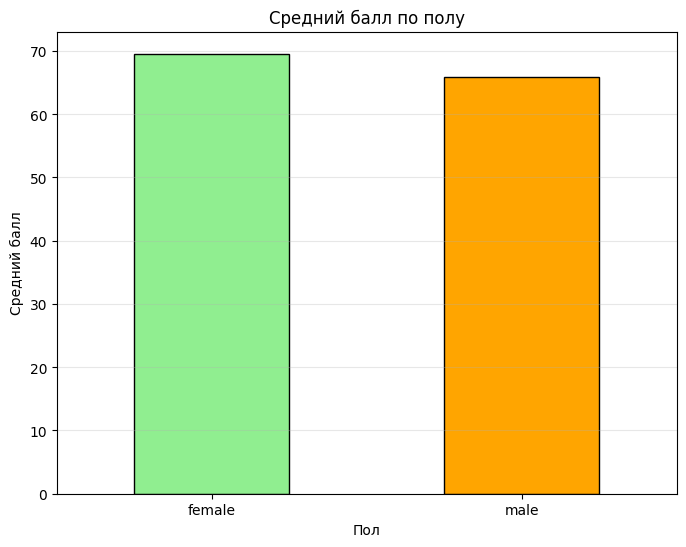

In [17]:
plt.figure(figsize=(8, 6))
gender_avg = df.groupby('gender')['average_score'].mean()
gender_avg.plot(kind='bar', color=['lightgreen', 'orange'], edgecolor='black')
plt.title('Средний балл по полу')
plt.xlabel('Пол')
plt.ylabel('Средний балл')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.show()

### Вывод по графику
Напишите 1–3 предложения.

In [18]:
# Женщины в среднем имеют более высокий средний балл, чем мужчины. 
# Разница между полами незначительна, но статистически заметна.

## 13. Визуализация 4 — диаграмма рассеяния

Постройте диаграмму рассеяния для зависимости между двумя числовыми признаками.

Обязательный вариант:
- `math_score` и `reading_score`

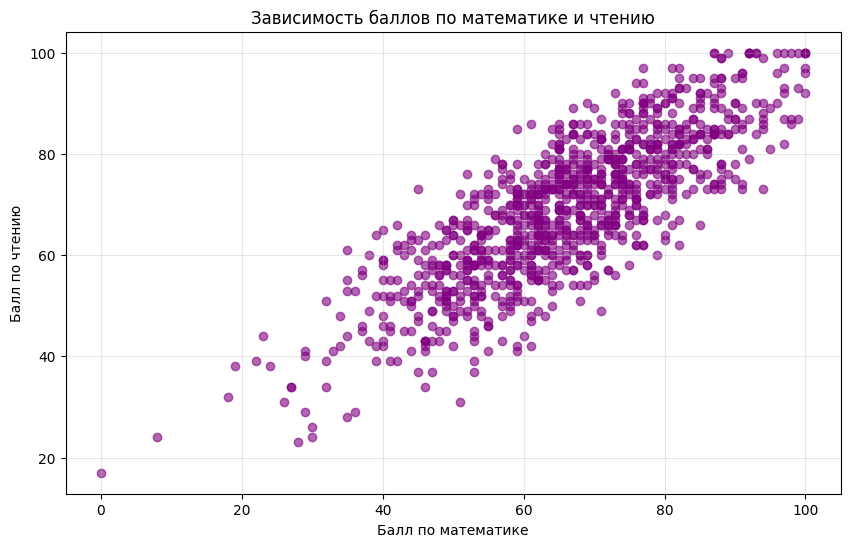

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(df['math_score'], df['reading_score'], alpha=0.6, color='purple')
plt.title('Зависимость баллов по математике и чтению')
plt.xlabel('Балл по математике')
plt.ylabel('Балл по чтению')
plt.grid(True, alpha=0.3)
plt.show()

### Вывод по графику
Напишите 1–3 предложения.

In [20]:
# Наблюдается положительная корреляция между баллами по математике и чтению. 
# Студенты с высокими баллами по математике обычно имеют высокие баллы и по чтению.

## 14. Дополнительная визуализация

Добавьте **еще один график самостоятельно**.

Можно выбрать один из вариантов:
- график по `parent_education`;
- график по `lunch`;
- boxplot;
- еще одна гистограмма;
- другой осмысленный вариант.

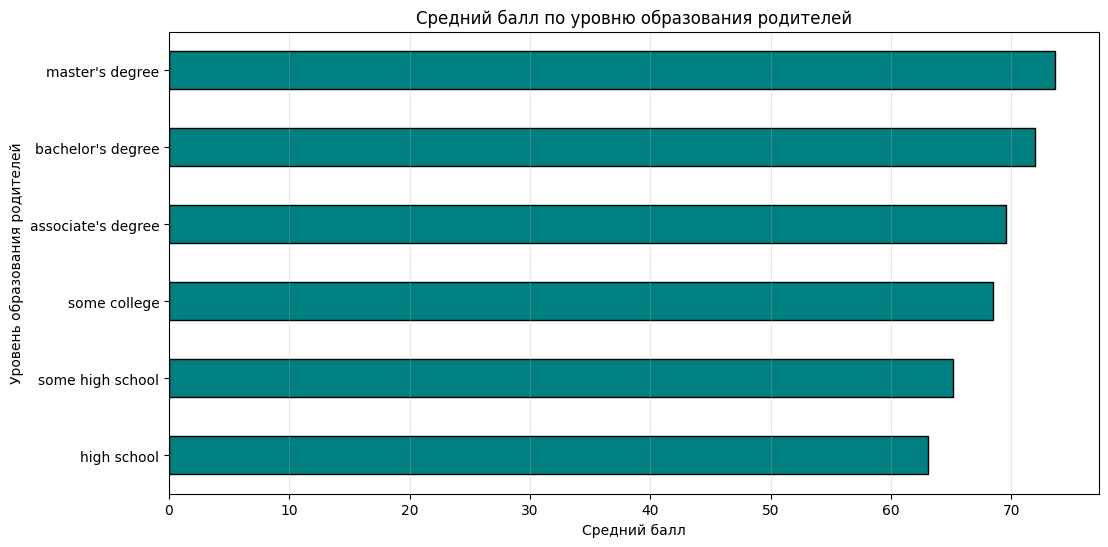

In [21]:
plt.figure(figsize=(12, 6))
parent_edu_avg = df.groupby('parent_education')['average_score'].mean().sort_values()
parent_edu_avg.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Средний балл по уровню образования родителей')
plt.xlabel('Средний балл')
plt.ylabel('Уровень образования родителей')
plt.grid(True, alpha=0.3, axis='x')
plt.show()

### Вывод по графику
Напишите 1–3 предложения.

In [22]:
# Студенты, чьи родители имеют степень магистра или бакалавра, показывают лучшие результаты. 
# Уровень образования родителей напрямую влияет на успеваемость детей.

## 15. Итоговый вывод

В финале кратко ответьте:
1. Что было сделано в работе?
2. Какие библиотеки и методы были использованы?
3. Какие закономерности удалось заметить?
4. Какие трудности возникли в процессе выполнения?

In [23]:
# 1. В работе был проведен анализ данных об успеваемости студентов: загрузка, очистка, 
#    создание новых признаков, группировка и визуализация.
# 2. Использованы библиотеки pandas, matplotlib, numpy. Применены методы groupby, 
#    describe, hist, plot, scatter.
# 3. Обнаружены закономерности: подготовка к тесту повышает баллы, женщины в среднем 
#    успевают лучше, образование родителей влияет на результаты.
# 4. Трудностей не возникло, данные были чистыми и готовыми к анализу.

## 16. Проверка перед сдачей

Перед отправкой убедитесь, что:
- все ячейки выполняются без ошибок;
- код написан последовательно и понятно;
- новые признаки действительно созданы вами;
- столбцы переименованы;
- построено не менее 4 обязательных графиков;
- под каждым графиком есть вывод;
- notebook сохранен после выполнения `Restart & Run All`.